# Fractional Volterra Stein–Stein: exploratory ATM-skew term structure

This notebook studies the ATM-skew term structure generated by the fractional Volterra Stein–Stein model. It is intentionally self-contained: all inputs below are user-defined model or exploratory inputs, and no market data, Excel file, calibration, or market-data extraction is used.

The left panel uses the constant deterministic curve set by `G0_CONSTANT`. The right panel uses the explicit positive piecewise-constant curve defined below. In both panels, the same fractional-kernel Fourier-pricing construction is used for every selected value of $\eta$.

For the one-dimensional model used here, $\rho=R_W=[1]$, $C=[c]$, and

$$
\begin{aligned}
W_t &= cB_t + \sqrt{1-c^2}\,B_t^\perp,\\
Y_t &= Y_0 + \eta\int_0^t K_H(t,s)\,dW_s,\\
\sigma(t,Y_t) &= G_0(t)\frac{Y_t}{\sqrt{\mathbb{E}[Y_t^2]}}.
\end{aligned}
$$

The scalar coefficient $c$ controls the price–volatility correlation.


In [2]:
from functools import lru_cache
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
from scipy.special import roots_laguerre

# Make the local src/ package importable when this notebook is run from the project directory.
PROJECT_ROOT = next((root for root in [Path.cwd(), *Path.cwd().parents]
                     if (root / 'src' / 'vss').is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Could not locate the repository root containing src/vss.')
SRC_PATH = PROJECT_ROOT / 'src'
if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

from vss.calibration.variance_swap_g0 import evaluate_piecewise_constant_g0_on_grid
from vss.fourier.flt_prefactor_free import matrix_sqrt_psd, vss_fourier_laplace_det_prefactor_free
from vss.fourier.parameters import compute_V_matrix_for_fourier, compute_tilde_g_N0
from vss.fourier.skew import skew_fourier
from vss.kernels.one_asset.shifted_fractional import shifted_fractional_KK_SIG_d1_n1
from vss.parameters import compute_M_matrix, compute_tilde_Gamma


## User-editable exploratory inputs

The maturity grid must remain strictly positive. The `etas` array contains positive volatility-of-volatility values for the first row, while `Hs` contains positive fractional parameters for the second row at fixed `eta=ETA_FIXED`. Both arrays can be edited. The two figures below use the same model parameters and differ only in the two-point `skew_moneyness` pair used to measure the ATM skew. The piecewise-constant curve is defined by `time_boundaries` and `G0_values`; there must be one value for each interval.

In [3]:
# Fixed model inputs requested for this experiment.
Y0 = 1.0
c = -0.8
H_FIXED = 0.45
G0_CONSTANT = 0.2
ETA_FIXED = 1.3

# User-editable inputs for the long-maturity power-law analysis.
ETA_LONG_TERM = 1.3
G0_LONG_TERM = 0.2
LONG_MATURITY_MIN = 1.0
# User-editable upper bound for the short-maturity power-law analysis.
SHORT_MATURITY_MAX = 0.10

# User-editable positive eta values, ordered from small to progressively larger values.
etas = np.array([0.20, 0.5, 1., 1.5], dtype=float) 
# User-editable positive H values for the second row, with eta fixed at ETA_FIXED.
Hs = np.array([0.10, 0.20, 0.35, 0.45], dtype=float)

# User-editable, strictly positive maturity grid in years.
maturities = np.geomspace(1.0 / 252, 15.0, 24)

# Two-point finite-difference definition of the ATM skew, as in vss_calibration.ipynb.
S_0 = 1.0
skew_moneyness_98_102 = np.array([0.98, 1.02], dtype=float)
log_moneyness_98_102 = np.log(skew_moneyness_98_102)

# Second moneyness pair for the otherwise identical 2 x 2 figure.
skew_moneyness_95_105 = np.array([0.95, 1.05], dtype=float)
log_moneyness_95_105 = np.log(skew_moneyness_95_105)

# Explicit user-defined piecewise-constant G0 curve.
# Interval k is [time_boundaries[k], time_boundaries[k + 1]).
time_boundaries = np.array([0.0, 0.10, 0.25, 0.50, 1.00, 2.00, 5.00], dtype=float)
G0_values = np.array([1.00, 0.92, 1.08, 0.96, 1.04, 0.99], dtype=float) / 5 # divide by 5 to get same order og magnitude than G0_CONSTANT=0.2

if not np.all(np.isfinite(etas)) or np.any(etas <= 0.0):
    raise ValueError('etas must contain only finite, strictly positive values.')
if not np.isfinite(ETA_FIXED) or ETA_FIXED <= 0.0:
    raise ValueError('ETA_FIXED must be finite and strictly positive.')
if not np.isfinite(ETA_LONG_TERM) or ETA_LONG_TERM <= 0.0:
    raise ValueError('ETA_LONG_TERM must be finite and strictly positive.')
if not np.isfinite(G0_LONG_TERM) or G0_LONG_TERM <= 0.0:
    raise ValueError('G0_LONG_TERM must be finite and strictly positive.')
if not np.isfinite(LONG_MATURITY_MIN) or LONG_MATURITY_MIN <= 0.0:
    raise ValueError('LONG_MATURITY_MIN must be finite and strictly positive.')
if not np.isfinite(SHORT_MATURITY_MAX) or SHORT_MATURITY_MAX <= 0.0:
    raise ValueError('SHORT_MATURITY_MAX must be finite and strictly positive.')
if np.count_nonzero(maturities >= LONG_MATURITY_MIN) < 3:
    raise ValueError('LONG_MATURITY_MIN must leave at least three maturities for the power-law fit.')
if np.count_nonzero(maturities <= SHORT_MATURITY_MAX) < 3:
    raise ValueError('SHORT_MATURITY_MAX must leave at least three maturities for the power-law fit.')
if not np.all(np.isfinite(maturities)) or np.any(maturities <= 0.0):
    raise ValueError('maturities must be finite and strictly positive.')
if not np.all(np.diff(maturities) > 0.0):
    raise ValueError('maturities must be strictly increasing.')
if time_boundaries[0] != 0.0 or not np.all(np.diff(time_boundaries) > 0.0):
    raise ValueError('time_boundaries must be strictly increasing and begin at zero.')
if len(G0_values) != len(time_boundaries) - 1:
    raise ValueError('G0_values must contain one value per piecewise-constant interval.')
if not np.all(np.isfinite(G0_values)) or np.any(G0_values <= 0.0):
    raise ValueError('G0_values must contain only finite, strictly positive values.')

print(f'{len(etas)} eta values at H={H_FIXED}, {len(Hs)} H values at eta={ETA_FIXED}, {len(maturities)} maturities')
print(f'Fixed inputs: c={c}, Y0={Y0}')
print('Piecewise G0 boundaries:', time_boundaries)
print('Piecewise G0 values:     ', G0_values)

4 eta values at H=0.45, 4 H values at eta=1.3, 24 maturities
Fixed inputs: c=-0.8, Y0=1.0
Piecewise G0 boundaries: [0.   0.1  0.25 0.5  1.   2.   5.  ]
Piecewise G0 values:      [0.2   0.184 0.216 0.192 0.208 0.198]


## Fourier-pricing setup

The following helper functions reproduce the fractional-kernel workflow used in the calibration notebook. The pure fractional kernel is obtained with `delta = 0`; `SIG_eta_free` is then scaled by $\eta^2$. The Fourier objects are rebuilt for each maturity, eta, and deterministic $G_0$ curve.

In [4]:
n = d = 1
rho = np.array([[1.0]])
R_W = np.array([[1.0]])
Gamma = np.array([[1.0]])
tilde_Gamma = compute_tilde_Gamma(n=n, d=d, Gamma=Gamma)

@lru_cache(maxsize=None)
def get_laguerre_rule(order):
    """Cache the Gauss–Laguerre nodes and weights used by the Fourier integral."""
    return roots_laguerre(int(order))


def fractional_time_grid_and_laguerre_rule_size(T, H_value):
    """Use the maturity/H-dependent resolution rule from vss_calibration.ipynb."""
    if T <= 0.01:
        N_base, Q_base = 20, 128
    elif T <= 0.10:
        N_base, Q_base = 30, 80
    elif T <= 0.50:
        N_base, Q_base = 40, 60
    elif T <= 1.0:
        N_base, Q_base = 50, 40
    else:
        N_base, Q_base = 90, 30

    if H_value <= 0.10:
        N_multiplier, Q_multiplier = 2.0, 0.50
    elif H_value <= 0.25:
        N_multiplier, Q_multiplier = 1.5, 0.75
    else:
        N_multiplier, Q_multiplier = 1.0, 1.0

    N = int(np.ceil(N_base * N_multiplier))
    Q_laguerre = max(int(np.floor(Q_base * Q_multiplier)), 20)
    return N, Q_laguerre


def g0_on_fourier_grid(T, N, curve_name):
    """Return G0(t_i) in the (N, 1, 1) format expected by compute_M_matrix."""
    if curve_name == 'constant':
        return np.full((N, 1, 1), G0_CONSTANT, dtype=float)
    if curve_name == 'piecewise':
        return evaluate_piecewise_constant_g0_on_grid(
            T, N, time_boundaries, G0_values
        )
    raise ValueError(f'Unknown G0 curve: {curve_name}')


def build_fractional_fourier_objects(T, N, eta, H_value, G0_grid):
    """Build KK, SIG, M, V, sqrt(V), and tilde_g for one Fourier calculation."""
    # Step 1: pure fractional kernel, with delta = 0.
    KK, SIG_eta_free = shifted_fractional_KK_SIG_d1_n1(
        N=N,
        T=T,
        H=H_value,
        delta=0.0,
    )

    eta_matrix = np.array([[eta]], dtype=float)
    SIG = np.kron(SIG_eta_free, eta_matrix @ eta_matrix.T)
    C_matrix = np.array([[c]], dtype=float)
    Y0_array = np.array([Y0], dtype=float)

    # Steps 2–3: covariance normalization and Fourier covariance matrix.
    MM = compute_M_matrix(
        n=n,
        d=d,
        N=N,
        SIG=SIG,
        Gamma=Gamma,
        tilde_Gamma=tilde_Gamma,
        rho=rho,
        G0=G0_grid,
        Y0=Y0_array,
    )
    V = compute_V_matrix_for_fourier(
        n=n,
        N=N,
        T=T,
        eta=eta_matrix,
        R_W=R_W,
        KK=KK,
        SIG=SIG,
        MM=MM,
    )
    sqrt_V = matrix_sqrt_psd(V)
    g_tilde = compute_tilde_g_N0(Y0_array, n, N, MM)
    return V, sqrt_V, g_tilde, C_matrix


## ATM skew and term structures

For each maturity, the Fourier–Laplace transform is evaluated at $u=0.5+i\ell$ and $w=0$ over the Gauss–Laguerre nodes $\ell$. The resulting transform is passed directly to `skew_fourier`, which returns the two-point implied-volatility slope around ATM.

In [5]:
def fractional_atm_skew(T, eta, H_value, curve_name, log_moneyness_value):
    """Compute the two-point ATM skew for one maturity and one G0 curve."""
    N, Q_laguerre = fractional_time_grid_and_laguerre_rule_size(T, H_value)
    nodes, weights = get_laguerre_rule(Q_laguerre)
    G0_grid = g0_on_fourier_grid(T, N, curve_name)

    V, sqrt_V, g_tilde, C_matrix = build_fractional_fourier_objects(
        T=T, N=N, eta=eta, H_value=H_value, G0_grid=G0_grid
    )

    # Step 4: Fourier–Laplace transform at the quadrature points.
    u_array = (0.5 + 1j * nodes).reshape(-1, 1)
    w_array = np.zeros((len(nodes), 1, 1), dtype=complex)
    transform_values = vss_fourier_laplace_det_prefactor_free(
        u_array,
        w_array,
        n,
        d,
        N,
        T,
        C_matrix,
        rho,
        R_W,
        V,
        sqrt_V,
        g_tilde,
    )

    # Step 5: convert the transform into the two-point ATM skew.
    return skew_fourier(
        transform_values,
        S_0,
        T,
        log_moneyness_value,
        nodes,
        weights,
    )


skews_by_eta = {}
for curve_name in ('constant', 'piecewise'):
    skews_by_eta[curve_name] = np.array(
        [
            [fractional_atm_skew(T, eta, H_FIXED, curve_name, log_moneyness_98_102) for T in maturities]
            for eta in etas
        ],
        dtype=float,
    )

skews_by_H = {}
for curve_name in ('constant', 'piecewise'):
    skews_by_H[curve_name] = np.array(
        [
            [fractional_atm_skew(T, ETA_FIXED, H_value, curve_name, log_moneyness_98_102) for T in maturities]
            for H_value in Hs
        ],
        dtype=float,
    )

# Repeat the same Fourier/skew calculation with only the moneyness pair changed.
skews_by_eta_95_105 = {}
for curve_name in ('constant', 'piecewise'):
    skews_by_eta_95_105[curve_name] = np.array(
        [
            [fractional_atm_skew(T, eta, H_FIXED, curve_name, log_moneyness_95_105) for T in maturities]
            for eta in etas
        ],
        dtype=float,
    )

skews_by_H_95_105 = {}
for curve_name in ('constant', 'piecewise'):
    skews_by_H_95_105[curve_name] = np.array(
        [
            [fractional_atm_skew(T, ETA_FIXED, H_value, curve_name, log_moneyness_95_105) for T in maturities]
            for H_value in Hs
        ],
        dtype=float,
    )

print('Computed eta-sweep array shape:', skews_by_eta['constant'].shape)
print('Computed H-sweep array shape:', skews_by_H['constant'].shape)
print('Constant G0 eta-sweep range:', np.nanmin(skews_by_eta['constant']), np.nanmax(skews_by_eta['constant']))
print('Piecewise G0 eta-sweep range:', np.nanmin(skews_by_eta['piecewise']), np.nanmax(skews_by_eta['piecewise']))
print('Constant G0 H-sweep range:', np.nanmin(skews_by_H['constant']), np.nanmax(skews_by_H['constant']))
print('Piecewise G0 H-sweep range:', np.nanmin(skews_by_H['piecewise']), np.nanmax(skews_by_H['piecewise']))
print('Computed [0.95, 1.05] eta-sweep array shape:', skews_by_eta_95_105['constant'].shape)
print('Computed [0.95, 1.05] H-sweep array shape:', skews_by_H_95_105['constant'].shape)

Computed eta-sweep array shape: (4, 24)
Computed H-sweep array shape: (4, 24)
Constant G0 eta-sweep range: -0.7835629451935895 -0.0629746014068305
Piecewise G0 eta-sweep range: -0.7835629451935895 -0.06275814570723469
Constant G0 H-sweep range: -2.6168099801579516 -0.029391777061723155
Piecewise G0 H-sweep range: -2.6168099801579516 -0.029340838641511983
Computed [0.95, 1.05] eta-sweep array shape: (4, 24)
Computed [0.95, 1.05] H-sweep array shape: (4, 24)


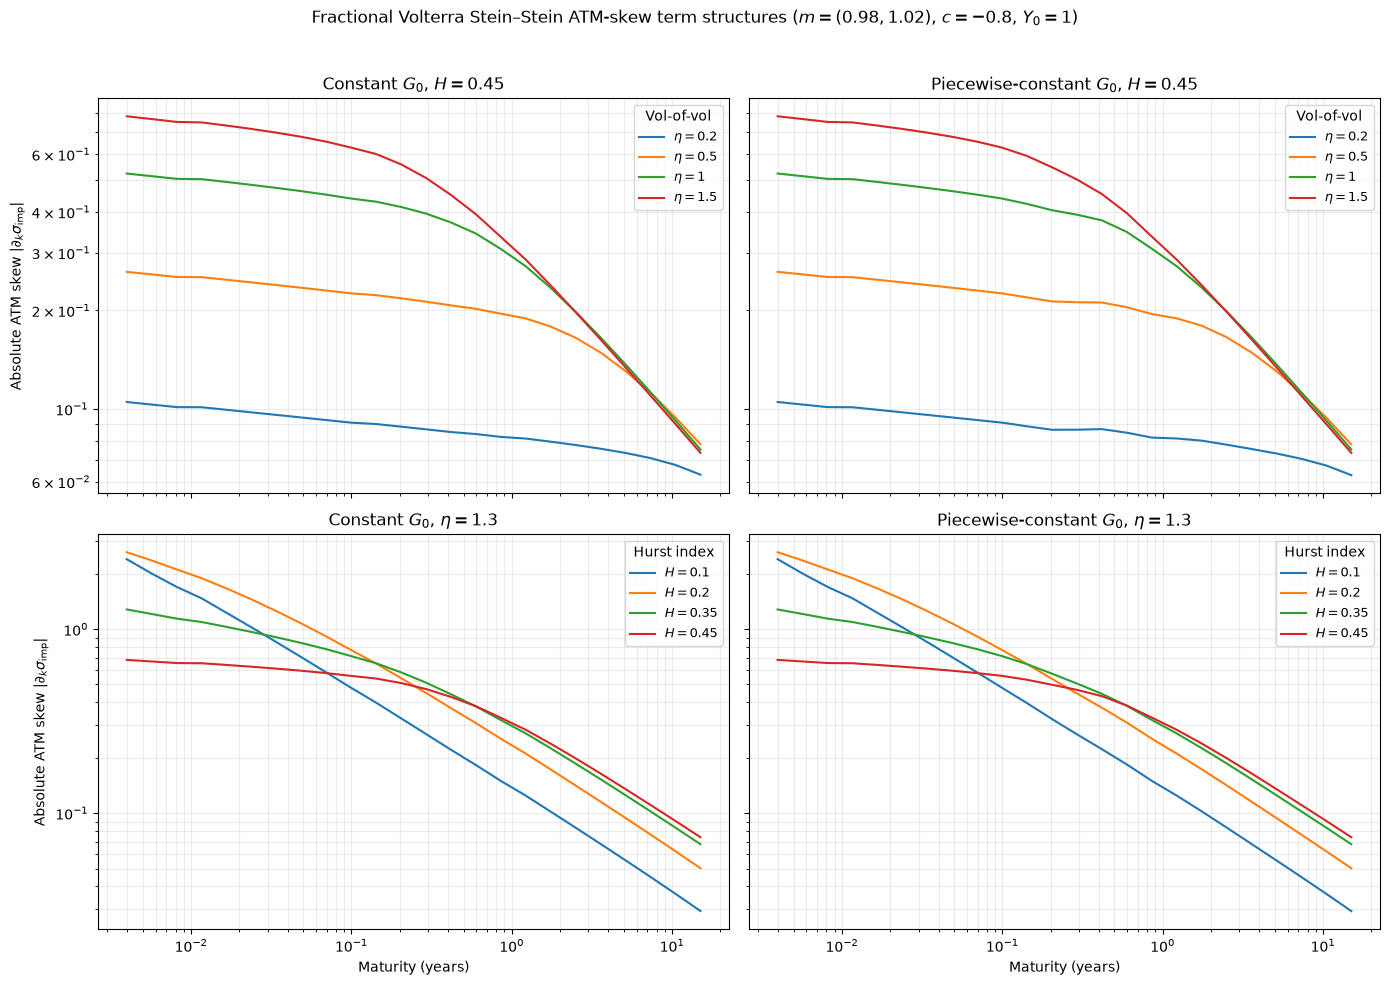

Saved figure to: /Users/maximeguellil/Library/Mobile Documents/com~apple~CloudDocs/Documents/Recherche/Codes/Volterra Stein-Stein/Multi dimension/Plots vss_fractional_atm_skew/atm_skew_sensi_to_H_eta_moneyness_0.98_1.02_eta_1.3.png


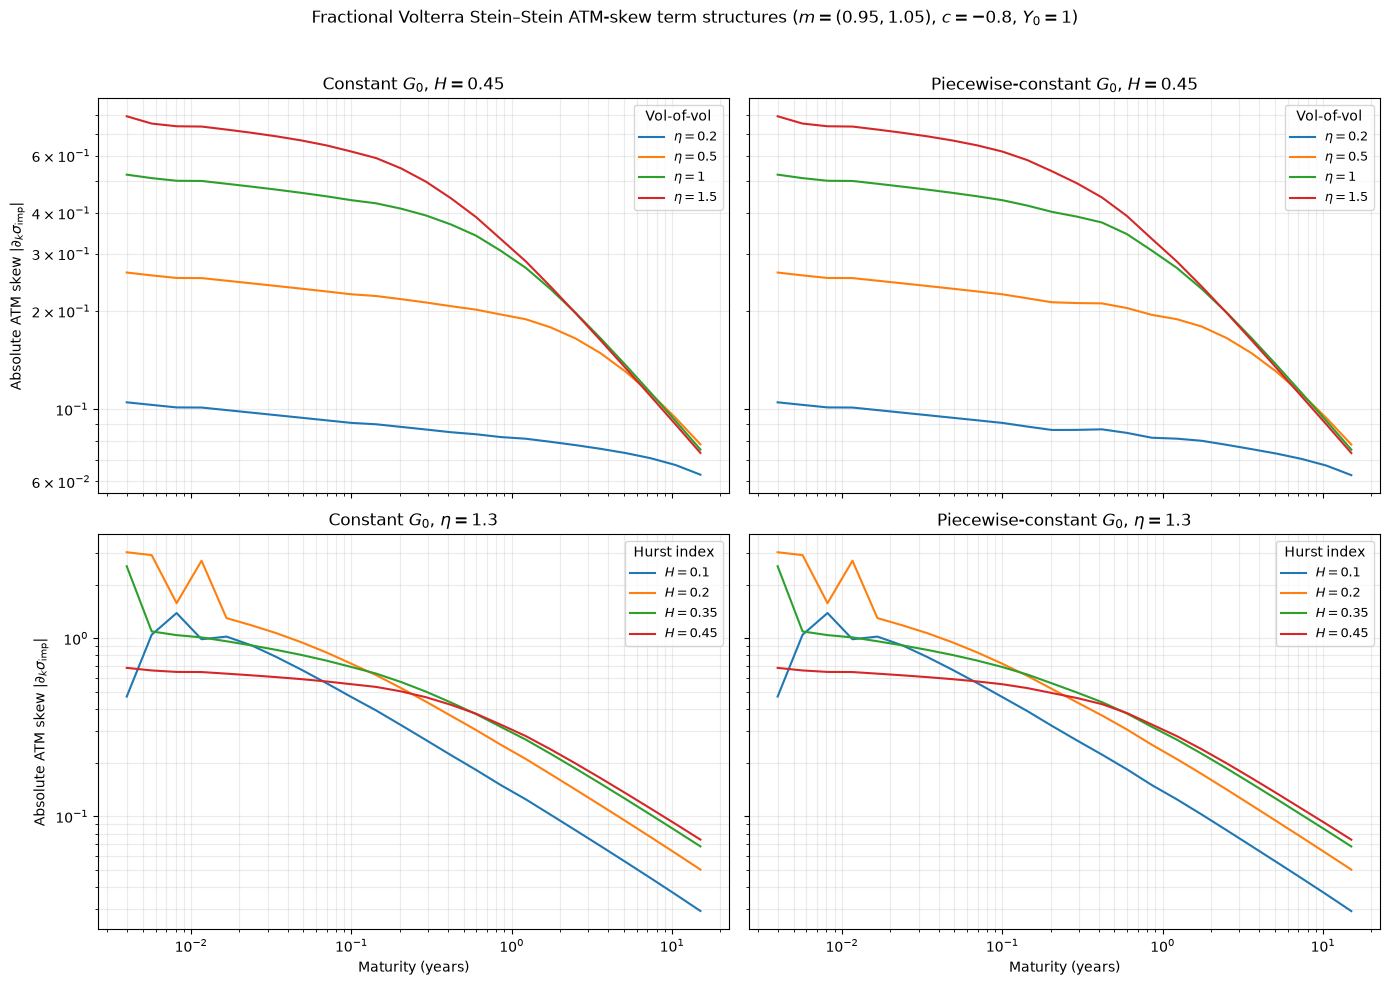

Saved figure to: /Users/maximeguellil/Library/Mobile Documents/com~apple~CloudDocs/Documents/Recherche/Codes/Volterra Stein-Stein/Multi dimension/Plots vss_fractional_atm_skew/atm_skew_sensi_to_H_eta_moneyness_0.95_1.05_eta_1.3.png


In [6]:
# Plot and save the 2 x 2 figure for skew_moneyness = [0.98, 1.02].
output_dir = PROJECT_ROOT / 'Plots vss_fractional_atm_skew'
output_dir.mkdir(parents=True, exist_ok=True)
figure_path_98_102 = output_dir / (
    f'atm_skew_sensi_to_H_eta_moneyness_0.98_1.02_eta_{ETA_FIXED:g}.png'
)

fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True, sharey='row')
curve_specs = (
    ('constant', r'Constant $G_0$'),
    ('piecewise', r'Piecewise-constant $G_0$'),
)

for col, (curve_name, title) in enumerate(curve_specs):
    ax = axes[0, col]
    for eta, skew_values in zip(etas, skews_by_eta[curve_name]):
        # A tiny positive floor only protects the logarithmic axis if a
        # user-selected parameter set produces an exact numerical zero.
        abs_skew = np.maximum(np.abs(skew_values), np.finfo(float).tiny)
        ax.loglog(maturities, abs_skew, ms=3.5, lw=1.5, label=fr'$\eta={eta:g}$')
    ax.set_title(title + fr', $H={H_FIXED:g}$')
    ax.grid(True, which='both', alpha=0.25)
    ax.legend(title='Vol-of-vol', fontsize=9)

    ax = axes[1, col]
    for H_value, skew_values in zip(Hs, skews_by_H[curve_name]):
        abs_skew = np.maximum(np.abs(skew_values), np.finfo(float).tiny)
        ax.loglog(maturities, abs_skew, ms=3.5, lw=1.5, label=fr'$H={H_value:g}$')
    ax.set_title(title + fr', $\eta={ETA_FIXED:g}$')
    ax.set_xlabel('Maturity (years)')
    ax.grid(True, which='both', alpha=0.25)
    ax.legend(title='Hurst index', fontsize=9)

axes[0, 0].set_ylabel(r'Absolute ATM skew $|\partial_k \sigma_{\mathrm{imp}}|$')
axes[1, 0].set_ylabel(r'Absolute ATM skew $|\partial_k \sigma_{\mathrm{imp}}|$')
fig.suptitle(fr'Fractional Volterra Stein–Stein ATM-skew term structures ($m=(0.98,1.02)$, $c={c:g}$, $Y_0=1$)')
fig.tight_layout(rect=(0, 0, 1, 0.96))
fig.savefig(figure_path_98_102, dpi=180, bbox_inches='tight')
plt.show()
print(f'Saved figure to: {figure_path_98_102}')

# Copy of the same 2 x 2 plot for skew_moneyness = [0.95, 1.05].
figure_path_95_105 = output_dir / (
    f'atm_skew_sensi_to_H_eta_moneyness_0.95_1.05_eta_{ETA_FIXED:g}.png'
)
fig_95_105, axes_95_105 = plt.subplots(2, 2, figsize=(14, 10), sharex=True, sharey='row')

for col, (curve_name, title) in enumerate(curve_specs):
    ax = axes_95_105[0, col]
    for eta, skew_values in zip(etas, skews_by_eta_95_105[curve_name]):
        abs_skew = np.maximum(np.abs(skew_values), np.finfo(float).tiny)
        ax.loglog(maturities, abs_skew, ms=3.5, lw=1.5, label=fr'$\eta={eta:g}$')
    ax.set_title(title + fr', $H={H_FIXED:g}$')
    ax.grid(True, which='both', alpha=0.25)
    ax.legend(title='Vol-of-vol', fontsize=9)

    ax = axes_95_105[1, col]
    for H_value, skew_values in zip(Hs, skews_by_H_95_105[curve_name]):
        abs_skew = np.maximum(np.abs(skew_values), np.finfo(float).tiny)
        ax.loglog(maturities, abs_skew, ms=3.5, lw=1.5, label=fr'$H={H_value:g}$')
    ax.set_title(title + fr', $\eta={ETA_FIXED:g}$')
    ax.set_xlabel('Maturity (years)')
    ax.grid(True, which='both', alpha=0.25)
    ax.legend(title='Hurst index', fontsize=9)

axes_95_105[0, 0].set_ylabel(r'Absolute ATM skew $|\partial_k \sigma_{\mathrm{imp}}|$')
axes_95_105[1, 0].set_ylabel(r'Absolute ATM skew $|\partial_k \sigma_{\mathrm{imp}}|$')
fig_95_105.suptitle(fr'Fractional Volterra Stein–Stein ATM-skew term structures ($m=(0.95,1.05)$, $c={c:g}$, $Y_0=1$)')
fig_95_105.tight_layout(rect=(0, 0, 1, 0.96))
fig_95_105.savefig(figure_path_95_105, dpi=180, bbox_inches='tight')
plt.show()
print(f'Saved figure to: {figure_path_95_105}')

## Long-maturity power-law fit

This additional experiment fixes the volatility-of-volatility and uses a constant $G_0$. The controls `ETA_LONG_TERM`, `G0_LONG_TERM`, and `LONG_MATURITY_MIN` are independent and user-editable. For each $H$ in `Hs`, the absolute skew is fitted on the long-maturity subset as

$$\log |\operatorname{skew}(T)| = \log A + p\log T,$$

so that $|\operatorname{skew}(T)|\approx A T^p$. The estimated exponent $p$ is then compared with the model Hurst parameter $H$. This slope analysis uses only the narrower moneyness window $[0.98, 1.02]$.

Long-term fit controls: $\eta$=1.3, $G_0$=0.2, T_min=1
moneyness   H        power p     p-H       R^2
0.98_1.02   0.10     -0.57475  -0.67475  0.99986
0.98_1.02   0.20     -0.57143  -0.77143  0.99989
0.98_1.02   0.35     -0.55356  -0.90356  0.99973
0.98_1.02   0.45     -0.53780  -0.98780  0.99944


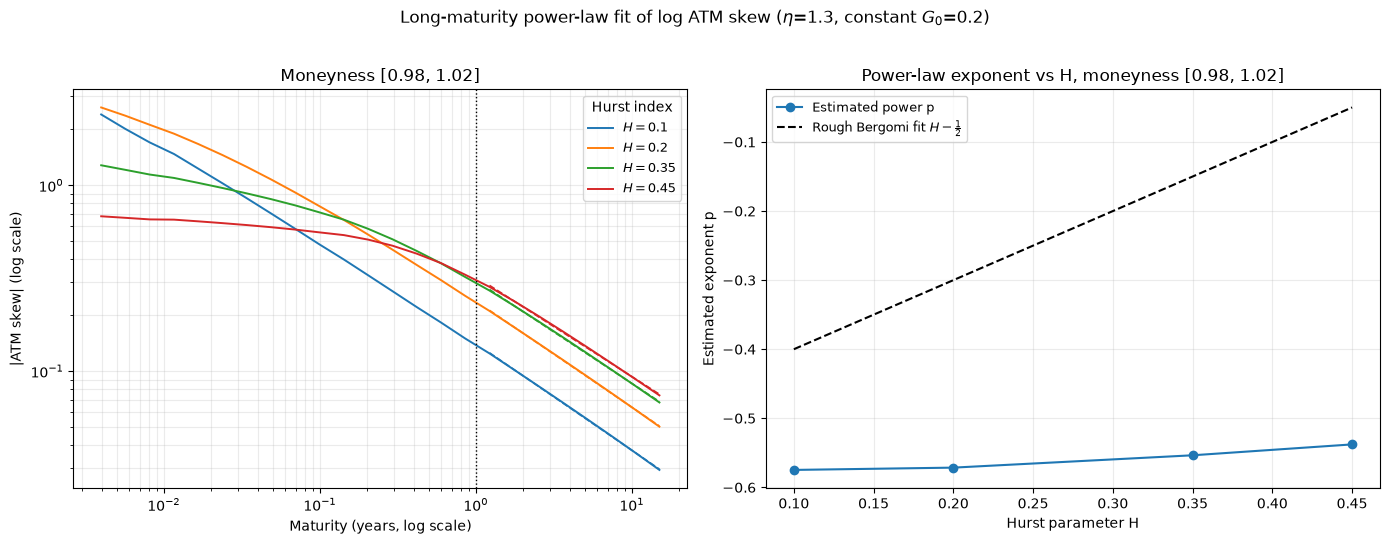

Saved power-law analysis figure to: /Users/maximeguellil/Library/Mobile Documents/com~apple~CloudDocs/Documents/Recherche/Codes/Volterra Stein-Stein/Multi dimension/Plots vss_fractional_atm_skew/fractional_atm_skew_long_term_power_law_moneyness_0.98_1.02_eta_1p3_G0_0p2.png


In [7]:
def fractional_atm_skew_for_constant_g0(T, eta, H_value, log_moneyness_value, g0_constant):
    """Compute the ATM skew for an explicitly supplied constant G0."""
    N, Q_laguerre = fractional_time_grid_and_laguerre_rule_size(T, H_value)
    nodes, weights = get_laguerre_rule(Q_laguerre)
    G0_grid = np.full((N, 1, 1), g0_constant, dtype=float)

    V, sqrt_V, g_tilde, C_matrix = build_fractional_fourier_objects(
        T=T, N=N, eta=eta, H_value=H_value, G0_grid=G0_grid
    )
    u_array = (0.5 + 1j * nodes).reshape(-1, 1)
    w_array = np.zeros((len(nodes), 1, 1), dtype=complex)
    transform_values = vss_fourier_laplace_det_prefactor_free(
        u_array, w_array, n, d, N, T, C_matrix, rho, R_W, V, sqrt_V, g_tilde
    )
    return skew_fourier(
        transform_values, S_0, T, log_moneyness_value, nodes, weights
    )


def fit_long_maturity_power_law(maturity_values, skew_values, maturity_min):
    """Fit abs(skew) = amplitude * T**power on maturities >= maturity_min."""
    maturity_values = np.asarray(maturity_values, dtype=float)
    skew_values = np.asarray(skew_values, dtype=float)
    fit_mask = maturity_values >= maturity_min
    if np.count_nonzero(fit_mask) < 3:
        raise ValueError('The long-maturity fit needs at least three maturities.')
    abs_skew = np.abs(skew_values)
    if not np.all(np.isfinite(abs_skew[fit_mask])) or np.any(abs_skew[fit_mask] <= 0.0):
        raise ValueError('The long-maturity skew values must be finite and non-zero.')

    log_maturities = np.log(maturity_values[fit_mask])
    log_abs_skew = np.log(abs_skew[fit_mask])
    power, log_amplitude = np.polyfit(log_maturities, log_abs_skew, deg=1)
    fitted_log_abs_skew = log_amplitude + power * log_maturities
    residuals = log_abs_skew - fitted_log_abs_skew
    r_squared = 1.0 - np.sum(residuals**2) / np.sum((log_abs_skew - np.mean(log_abs_skew))**2)
    return {
        'power': float(power),
        'amplitude': float(np.exp(log_amplitude)),
        'r_squared': float(r_squared),
        'fit_mask': fit_mask,
    }


moneyness_specs = (
    ('0.98_1.02', skew_moneyness_98_102, log_moneyness_98_102),
)
long_term_skews = {}
long_term_fits = {}
for moneyness_name, _, log_moneyness_value in moneyness_specs:
    long_term_skews[moneyness_name] = np.array(
        [
            [
                fractional_atm_skew_for_constant_g0(
                    T, ETA_LONG_TERM, H_value, log_moneyness_value, G0_LONG_TERM
                )
                for T in maturities
            ]
            for H_value in Hs
        ],
        dtype=float,
    )
    long_term_fits[moneyness_name] = [
        fit_long_maturity_power_law(maturities, skew_values, LONG_MATURITY_MIN)
        for skew_values in long_term_skews[moneyness_name]
    ]

print(
    rf'Long-term fit controls: $\eta$={ETA_LONG_TERM:g}, $G_0$={G0_LONG_TERM:g}, '
    f'T_min={LONG_MATURITY_MIN:g}'
)
print('moneyness   H        power p     p-H       R^2')
for moneyness_name, _, _ in moneyness_specs:
    for H_value, fit in zip(Hs, long_term_fits[moneyness_name]):
        print(
            f'{moneyness_name:>9}  {H_value:5.2f}    '
            f'{fit["power"]:9.5f}  {fit["power"] - H_value:8.5f}  '
            f'{fit["r_squared"]:7.5f}'
        )

eta_tag = f'{ETA_LONG_TERM:g}'.replace('.', 'p')
g0_tag = f'{G0_LONG_TERM:g}'.replace('.', 'p')
powerlaw_figure_path = output_dir / (
    f'fractional_atm_skew_long_term_power_law_moneyness_0.98_1.02_eta_{eta_tag}_G0_{g0_tag}.png'
)

fig_powerlaw, axes_powerlaw = plt.subplots(1, 2, figsize=(14, 5.5))
moneyness_name, moneyness_values, _ = moneyness_specs[0]
ax_fit = axes_powerlaw[0]
for H_value, skew_values, fit in zip(
    Hs, long_term_skews[moneyness_name], long_term_fits[moneyness_name]
):
    abs_skew = np.maximum(np.abs(skew_values), np.finfo(float).tiny)
    line, = ax_fit.loglog(
        maturities, abs_skew, ms=3.5, lw=1.4,
        label=fr'$H={H_value:g}$'
    )
    fit_maturities = maturities[fit['fit_mask']]
    ax_fit.loglog(
        fit_maturities, fit['amplitude'] * fit_maturities**fit['power'],
        '--', color=line.get_color(), lw=1.2
    )
ax_fit.axvline(LONG_MATURITY_MIN, color='k', ls=':', lw=1.0)
ax_fit.set_title(
    fr'Moneyness [{moneyness_values[0]:g}, {moneyness_values[1]:g}]'
)
ax_fit.set_xlabel('Maturity (years, log scale)')
ax_fit.set_ylabel(r'$|\mathrm{ATM\ skew}|$ (log scale)')
ax_fit.grid(True, which='both', alpha=0.25)
ax_fit.legend(title='Hurst index', fontsize=9)

ax_power = axes_powerlaw[1]
powers = np.array([fit['power'] for fit in long_term_fits[moneyness_name]])
ax_power.plot(Hs, powers,'-o', label='Estimated power p')
ax_power.plot(Hs, Hs-1/2, 'k--', label=r'Rough Bergomi fit $H-\frac{1}{2}$')
ax_power.set_title(
    fr'Power-law exponent vs H, moneyness [{moneyness_values[0]:g}, {moneyness_values[1]:g}]'
)
ax_power.set_xlabel('Hurst parameter H')
ax_power.set_ylabel('Estimated exponent p')
ax_power.grid(True, alpha=0.25)
ax_power.legend(fontsize=9)

fig_powerlaw.suptitle(
    fr'Long-maturity power-law fit of log ATM skew '
    fr'($\eta$={ETA_LONG_TERM:g}, constant $G_0$={G0_LONG_TERM:g})'
)
fig_powerlaw.tight_layout(rect=(0, 0, 1, 0.96))
fig_powerlaw.savefig(powerlaw_figure_path, dpi=180, bbox_inches='tight')
plt.show()
print(f'Saved power-law analysis figure to: {powerlaw_figure_path}')

## Short-maturity power-law fit

This additional experiment uses the same controls and the same narrower moneyness window $[0.98, 1.02]$ as the long-maturity analysis, but fits the absolute ATM skew on the short-maturity subset $T\leq$ `SHORT_MATURITY_MAX`. The upper bound is user-editable. The figure deliberately keeps the same two-panel layout, labels, markers, fit lines, and reference line as the long-maturity figure.

Short-term fit controls: eta=1.3, G0=0.2, T_max=0.1
moneyness   H        power p     p-H       R^2
0.98_1.02   0.10     -0.49722  -0.59722  0.99872
0.98_1.02   0.20     -0.37958  -0.57958  0.99291
0.98_1.02   0.35     -0.17765  -0.52765  0.99223
0.98_1.02   0.45     -0.05961  -0.50961  0.97215


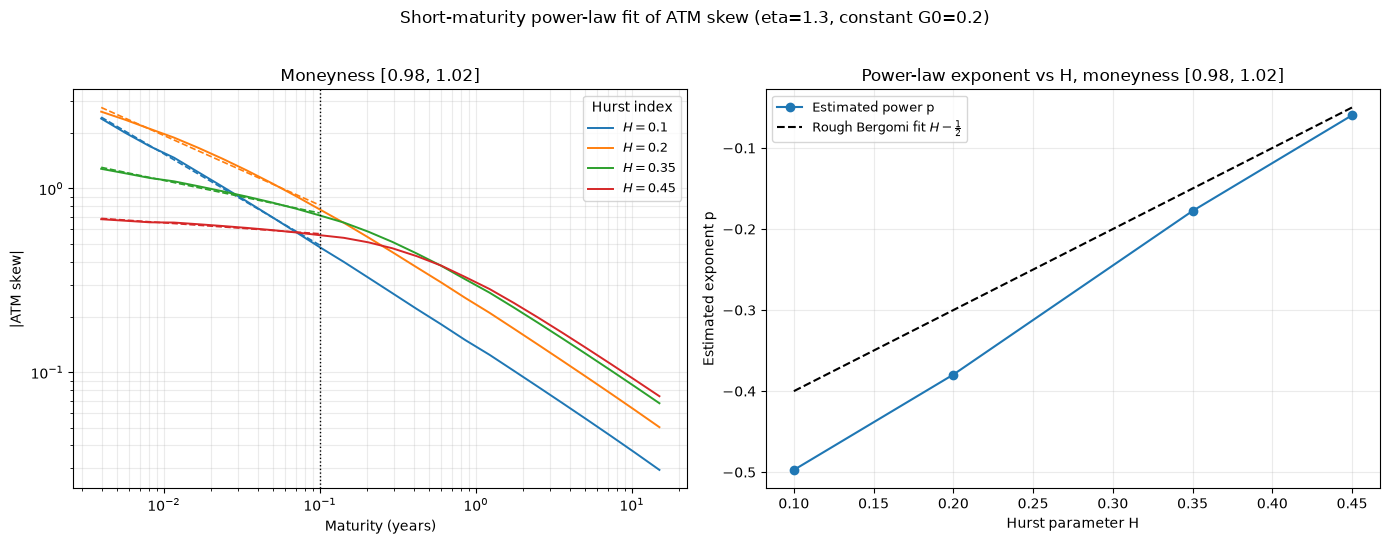

Saved short-maturity power-law analysis figure to: /Users/maximeguellil/Library/Mobile Documents/com~apple~CloudDocs/Documents/Recherche/Codes/Volterra Stein-Stein/Multi dimension/Plots vss_fractional_atm_skew/fractional_atm_skew_short_term_power_law_moneyness_0.98_1.02_eta_1p3_G0_0p2.png


In [8]:
def fit_short_maturity_power_law(maturity_values, skew_values, maturity_max):
    '''Fit abs(skew) = amplitude * T**power on maturities <= maturity_max.'''
    maturity_values = np.asarray(maturity_values, dtype=float)
    skew_values = np.asarray(skew_values, dtype=float)
    fit_mask = maturity_values <= maturity_max
    if np.count_nonzero(fit_mask) < 3:
        raise ValueError('The short-maturity fit needs at least three maturities.')
    abs_skew = np.abs(skew_values)
    if not np.all(np.isfinite(abs_skew[fit_mask])) or np.any(abs_skew[fit_mask] <= 0.0):
        raise ValueError('The short-maturity skew values must be finite and non-zero.')

    log_maturities = np.log(maturity_values[fit_mask])
    log_abs_skew = np.log(abs_skew[fit_mask])
    power, log_amplitude = np.polyfit(log_maturities, log_abs_skew, deg=1)
    fitted_log_abs_skew = log_amplitude + power * log_maturities
    residuals = log_abs_skew - fitted_log_abs_skew
    r_squared = 1.0 - np.sum(residuals**2) / np.sum((log_abs_skew - np.mean(log_abs_skew))**2)
    return {
        'power': float(power),
        'amplitude': float(np.exp(log_amplitude)),
        'r_squared': float(r_squared),
        'fit_mask': fit_mask,
    }

short_term_skews = {}
short_term_fits = {}
for moneyness_name, _, log_moneyness_value in moneyness_specs:
    short_term_skews[moneyness_name] = np.array(
        [
            [
                fractional_atm_skew_for_constant_g0(
                    T, ETA_LONG_TERM, H_value, log_moneyness_value, G0_LONG_TERM
                )
                for T in maturities
            ]
            for H_value in Hs
        ],
        dtype=float,
    )
    short_term_fits[moneyness_name] = [
        fit_short_maturity_power_law(maturities, skew_values, SHORT_MATURITY_MAX)
        for skew_values in short_term_skews[moneyness_name]
    ]

print(
    f'Short-term fit controls: eta={ETA_LONG_TERM:g}, G0={G0_LONG_TERM:g}, '
    f'T_max={SHORT_MATURITY_MAX:g}'
)
print('moneyness   H        power p     p-H       R^2')
for moneyness_name, _, _ in moneyness_specs:
    for H_value, fit in zip(Hs, short_term_fits[moneyness_name]):
        fit_power = fit['power']
        fit_r_squared = fit['r_squared']
        fit_difference = fit_power - H_value
        print(
            f'{moneyness_name:>9}  {H_value:5.2f}    '
            f'{fit_power:9.5f}  {fit_difference:8.5f}  '
            f'{fit_r_squared:7.5f}'
        )

eta_tag = f'{ETA_LONG_TERM:g}'.replace('.', 'p')
g0_tag = f'{G0_LONG_TERM:g}'.replace('.', 'p')
short_powerlaw_figure_path = output_dir / (
    f'fractional_atm_skew_short_term_power_law_moneyness_0.98_1.02_eta_{eta_tag}_G0_{g0_tag}.png'
)

fig_short_powerlaw, axes_short_powerlaw = plt.subplots(1, 2, figsize=(14, 5.5))
moneyness_name, moneyness_values, _ = moneyness_specs[0]
ax_fit = axes_short_powerlaw[0]
for H_value, skew_values, fit in zip(
    Hs, short_term_skews[moneyness_name], short_term_fits[moneyness_name]
):
    abs_skew = np.maximum(np.abs(skew_values), np.finfo(float).tiny)
    line, = ax_fit.loglog(
        maturities, abs_skew, ms=3.5, lw=1.4,
        label=fr'$H={H_value:g}$'
    )
    fit_maturities = maturities[fit['fit_mask']]
    ax_fit.loglog(
        fit_maturities, fit['amplitude'] * fit_maturities**fit['power'],
        '--', color=line.get_color(), lw=1.2
    )
ax_fit.axvline(SHORT_MATURITY_MAX, color='k', ls=':', lw=1.0)
ax_fit.set_title(
    fr'Moneyness [{moneyness_values[0]:g}, {moneyness_values[1]:g}]'
)
ax_fit.set_xlabel('Maturity (years)')
ax_fit.set_ylabel(r'$|\mathrm{ATM\ skew}|$')
ax_fit.grid(True, which='both', alpha=0.25)
ax_fit.legend(title='Hurst index', fontsize=9)

ax_power = axes_short_powerlaw[1]
powers = np.array([fit['power'] for fit in short_term_fits[moneyness_name]])
ax_power.plot(Hs, powers,'-o', label='Estimated power p')
ax_power.plot(Hs, Hs-1/2, 'k--', label=r'Rough Bergomi fit $H-\frac{1}{2}$')
ax_power.set_title(
    fr'Power-law exponent vs H, moneyness [{moneyness_values[0]:g}, {moneyness_values[1]:g}]'
)
ax_power.set_xlabel('Hurst parameter H')
ax_power.set_ylabel('Estimated exponent p')
ax_power.grid(True, alpha=0.25)
ax_power.legend(fontsize=9)

fig_short_powerlaw.suptitle(
    fr'Short-maturity power-law fit of ATM skew '
    fr'(eta={ETA_LONG_TERM:g}, constant G0={G0_LONG_TERM:g})'
)
fig_short_powerlaw.tight_layout(rect=(0, 0, 1, 0.96))
fig_short_powerlaw.savefig(short_powerlaw_figure_path, dpi=180, bbox_inches='tight')
plt.show()
print(f'Saved short-maturity power-law analysis figure to: {short_powerlaw_figure_path}')